<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 25: Restricted Boltzmann Machine Energy and Reconstruction

**Category**: CO5 – Energy-Based and Generative Models  
**Objective**: Implement a Restricted Boltzmann Machine (RBM), compute configuration energy, and optimize binary reconstruction fidelity.


### Task 1: Binary RBM Architecture and Energy Formulation


In [1]:
import numpy as np
import matplotlib.pyplot as plt

class RestrictedBoltzmannMachine:
    def __init__(self, n_vis=16, n_hid=8, lr=0.08, seed=42):
        np.random.seed(seed)
        self.n_vis = n_vis
        self.n_hid = n_hid
        self.lr = lr
        # Weight and bias initialization
        self.W = np.random.normal(0, 0.1, (n_vis, n_hid))
        self.a_vis = np.zeros(n_vis)
        self.b_hid = np.zeros(n_hid)

    def sigmoid(self, x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -15, 15)))

    def sample_hidden(self, v):
        p_h = self.sigmoid(np.dot(v, self.W) + self.b_hid)
        h_sample = (np.random.rand(*p_h.shape) < p_h).astype(float)
        return p_h, h_sample

    def sample_visible(self, h):
        p_v = self.sigmoid(np.dot(h, self.W.T) + self.a_vis)
        v_sample = (np.random.rand(*p_v.shape) < p_v).astype(float)
        return p_v, v_sample

    def compute_energy(self, v, h):
        # E(v, h) = -v^T * W * h - a^T * v - b^T * h
        term1 = -np.sum(np.dot(v, self.W) * h, axis=1)
        term2 = -np.dot(v, self.a_vis)
        term3 = -np.dot(h, self.b_hid)
        return term1 + term2 + term3

    def free_energy(self, v):
        # F(v) = -a^T * v - sum(log(1 + exp(v * W + b)))
        wx_b = np.dot(v, self.W) + self.b_hid
        return -np.dot(v, self.a_vis) - np.sum(np.log(1.0 + np.exp(wx_b)), axis=1)

rbm = RestrictedBoltzmannMachine(n_vis=16, n_hid=8)
print(f"RBM Constructed with {rbm.n_vis} Visible Units and {rbm.n_hid} Hidden Units.")


RBM Constructed with 16 Visible Units and 8 Hidden Units.


### Task 2: Train RBM and Monitor Reconstruction Error


In [2]:
# Generate synthetic binary patterns
np.random.seed(101)
n_patterns = 180
V_data = (np.random.rand(n_patterns, 16) < 0.35).astype(float)

rec_errors = []
epochs = 80

for ep in range(epochs):
    # 1. Positive phase
    p_h0, h0 = rbm.sample_hidden(V_data)

    # 2. Negative phase (1-step reconstruction)
    p_v1, v1 = rbm.sample_visible(h0)
    p_h1, h1 = rbm.sample_hidden(v1)

    # Parameter update gradients
    pos_grad = np.dot(V_data.T, p_h0) / n_patterns
    neg_grad = np.dot(v1.T, p_h1) / n_patterns

    rbm.W += rbm.lr * (pos_grad - neg_grad)
    rbm.a_vis += rbm.lr * np.mean(V_data - v1, axis=0)
    rbm.b_hid += rbm.lr * np.mean(p_h0 - p_h1, axis=0)

    mse_rec = np.mean((V_data - p_v1) ** 2)
    rec_errors.append(mse_rec)

print(f"RBM Training Complete. Initial MSE: {rec_errors[0]:.4f} -> Final MSE: {rec_errors[-1]:.4f}")


RBM Training Complete. Initial MSE: 0.2504 -> Final MSE: 0.2220


### Task 3: Plot Reconstruction Learning Curve and Energy Distribution


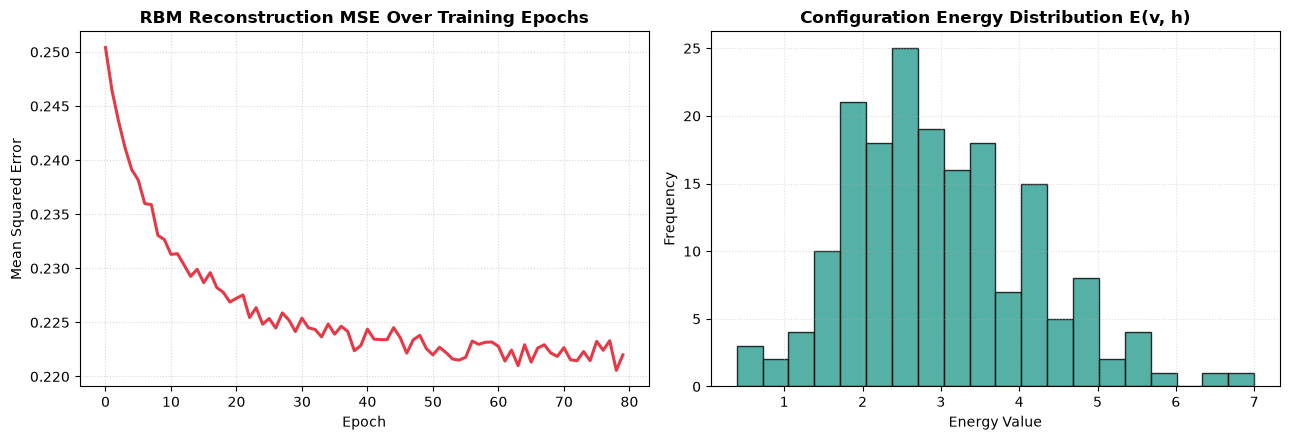

In [3]:
sample_h = rbm.sample_hidden(V_data)[1]
energies = rbm.compute_energy(V_data, sample_h)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(rec_errors, color='#e63946', lw=2.2)
axes[0].set_title("RBM Reconstruction MSE Over Training Epochs", fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error")
axes[0].grid(True, linestyle=':', alpha=0.5)

axes[1].hist(energies, bins=20, color='#2a9d8f', edgecolor='k', alpha=0.8)
axes[1].set_title("Configuration Energy Distribution E(v, h)", fontweight='bold')
axes[1].set_xlabel("Energy Value")
axes[1].set_ylabel("Frequency")
axes[1].grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()
